# 실습 5. 통계 지표 예측: 통계 모형 vs 딥러닝 vs 시계열 파운데이션 모델
**통계청 AI 교육 · 2026.10.27(화)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sunghoonim/stat-ai-2026/blob/main/lab5_time_series_forecasting.ipynb)

### 오늘의 목표
- 통계청이 작성하는 **월별 지표 4개**를 12개월 앞까지 예측한다
- 세 종류의 방법을 **같은 기준으로** 비교한다
  1. 통계 모형: 계절 naive, 지수평활(ETS), SARIMA
  2. 딥러닝을 **처음부터**: 신경망(MLP)
  3. **시계열 파운데이션 모델**(Chronos): 수많은 시계열로 미리 학습한 모델을 **학습 없이** 사용
- 모델 크기를 바꿔 보고, **예측 구간**이 믿을 만한지 확인한다
- 예측을 **이상값 검토**(내검)에 써 본다

| 단계 | 내용 | 시간 |
|---|---|---|
| 1단계 | 데이터 보기 | 2분 |
| 2단계 | 통계 모형으로 예측 (계절 naive · ETS · SARIMA) | 5분 |
| 3단계 | 신경망(MLP)을 처음부터 학습 | 3분 |
| 4단계 | 시계열 파운데이션 모델 (Chronos) | 5분 |
| 5단계 | 공정한 비교: 지표 4개 × 예측 시점 8개 | 4분 |
| 6단계 | 예측 구간은 믿을 만한가? | 3분 |
| 7단계 | 예측으로 이상값 찾기 (내검) | 3분 |

**합계 25분** · 실습 2 다음에 실습 3~5 중 1~2개를 골라서 합니다. 오래 걸리는 칸은 저장된 결과를 보면 됩니다.

### 사용법
1. 메뉴 **런타임 → 런타임 유형 변경 → CPU** (GPU는 필요 없습니다)
2. 메뉴 **런타임 → 모두 실행**. 처음에는 Chronos 설치와 모델 다운로드로 1~2분 걸립니다.
3. 이 노트북에는 **실행 결과가 미리 저장되어 있습니다.** 실행이 막혀도 결과를 보며 따라오세요.
4. 그림 속 글자는 영어입니다. Colab 기본 글꼴에 한글이 없어서 그렇습니다.

## 0. 준비

In [1]:
#@title Chronos 설치 (Colab에는 없어서 처음 한 번 설치합니다, 약 30초)
import subprocess, sys
try:
    import chronos
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "chronos-forecasting"], check=True)
    import chronos
print("chronos-forecasting", chronos.__version__ if hasattr(chronos, "__version__") else "설치 완료")

chronos-forecasting 2.3.2


In [2]:
import warnings; warnings.filterwarnings("ignore")
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import statsmodels
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from chronos import BaseChronosPipeline, Chronos2Pipeline

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
H = 12                 # 12개월 앞까지 예측
t_start = time.time()
print("PyTorch", torch.__version__, "| statsmodels", statsmodels.__version__)

PyTorch 2.14.1 | statsmodels 0.15.0


In [3]:
#@title 🎨 그림 도우미 함수 (실행만 하세요)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
EN = {"실업률": "Unemployment rate (%)", "취업자": "Employed persons (10,000)",
      "소매판매": "Retail sales volume index", "제조업생산": "Manufacturing production index"}
COLORS = {"계절 naive": "#999999", "ETS": "C0", "SARIMA": "C1", "MLP": "C3",
          "Chronos-Bolt": "C2", "Chronos-2": "C4"}
LABEL_EN = {"계절 naive": "seasonal naive", "ETS": "ETS", "SARIMA": "SARIMA", "MLP": "MLP",
            "Chronos-Bolt": "Chronos-Bolt", "Chronos-2": "Chronos-2"}

def plot_forecasts(y, fc, band=None, title="", years=4):
    """최근 몇 년 실제값 + 마지막 12개월 예측들. band = (모델 이름, 하한, 상한)"""
    fig, ax = plt.subplots(figsize=(9, 3.6))
    recent = y[-(12 * years):]
    ax.plot(recent.index, recent.values, "k", lw=1.6, label="actual")
    idx = y.index[-H:]
    for name, f in fc.items():
        ax.plot(idx, f, color=COLORS.get(name), lw=1.4, ls="--" if name == "계절 naive" else "-",
                label=LABEL_EN.get(name, name))
    if band:
        name, lo, hi = band
        ax.fill_between(idx, lo, hi, color=COLORS.get(name), alpha=0.15, label=f"{LABEL_EN.get(name, name)} 80% interval")
    ax.axvline(idx[0], color="k", lw=0.8, ls=":")
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7, ncol=3, loc="upper left")
    fig.tight_layout(); plt.show()

---
## 1단계. 데이터 보기 (2분)
통계청이 작성해 OECD에 제공하는 **월별 원계열**(계절조정 전) 4개를 씁니다. 미국 세인트루이스 연준의 공개 데이터베이스(FRED)에서 받습니다.

| 이름 | 지표 | 작성 통계 | 기간 |
|---|---|---|---|
| 실업률 | 실업률 (15세 이상, %) | 경제활동인구조사 | 2000.1 ~ 최근 |
| 취업자 | 취업자 수 (15세 이상, 만 명) | 경제활동인구조사 | 2000.1 ~ 최근 |
| 소매판매 | 소매판매액지수 (불변, 자동차 제외) | 산업활동동향 | 2000.1 ~ 2024.3 |
| 제조업생산 | 제조업 생산지수 | 산업활동동향 | 2000.1 ~ 2024.3 |

(소매판매·제조업생산은 OECD 쪽 갱신이 2024년 3월에 멈춰서 거기까지만 있습니다.)

In [4]:
#@title 데이터 내려받기 (FRED, 약 50KB)
DATA_CSV_URL = None   # 여기에 CSV 주소를 넣으면 FRED 대신 그 CSV를 씁니다
BACKUP_CSV_URL = "https://raw.githubusercontent.com/sunghoonim/stat-ai-2026/main/data/kr_monthly_indicators.csv"   # FRED 접속이 안 되면 자동으로 쓰는 저장소 사본 (FRED에서 받은 값과 같음)

SERIES = {"실업률": "LRHUTTTTKRM156N", "취업자": "LFEMTTTTKRM647N",
          "소매판매": "KORSLRTTO01IXOBM", "제조업생산": "KORPRMNTO01IXOBM"}

def load_series():
    if DATA_CSV_URL:
        df = pd.read_csv(DATA_CSV_URL, index_col=0, parse_dates=True)
    else:
        try:
            url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}"
            df = pd.concat({k: pd.read_csv(url.format(v), index_col=0, parse_dates=True).iloc[:, 0]
                            for k, v in SERIES.items()}, axis=1, sort=True)
            df["취업자"] = df["취업자"] / 1e4                  # 명 → 만 명
        except Exception as e:
            print(f"FRED 접속 실패({type(e).__name__}) → 저장소 사본 CSV를 씁니다")
            df = pd.read_csv(BACKUP_CSV_URL, index_col=0, parse_dates=True)
    df = df[df.index >= "2000-01-01"]
    return {k: df[k].dropna().astype(float).asfreq("MS") for k in SERIES}

data = load_series()
pd.DataFrame({k: {"시작": s.index[0].strftime("%Y.%m"), "끝": s.index[-1].strftime("%Y.%m"), "개월 수": len(s),
                  "평균": round(s.mean(), 1), "최근값": round(s.iloc[-1], 1)} for k, s in data.items()}).T

,시작,끝,개월 수,평균,최근값
실업률,2000.01,2026.08,320,3.5,2.0
취업자,2000.01,2026.08,320,2520.7,2915.1
소매판매,2000.01,2024.03,291,91.2,117.6
제조업생산,2000.01,2024.03,291,88.0,119.2


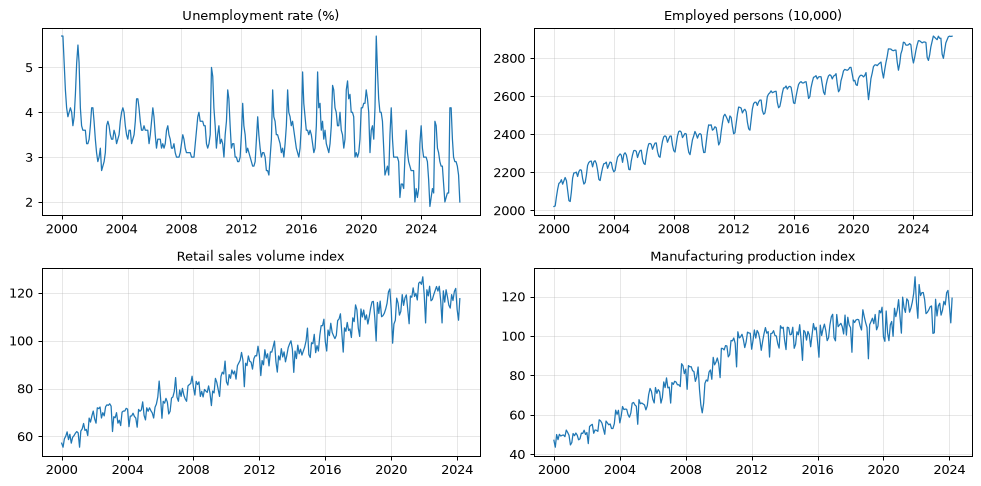

,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
실업률,+0.59,+0.79,+0.39,+0.22,+0.02,+0.02,-0.14,-0.50,-0.44,-0.47,-0.58,-0.00
취업자,-84.61,-68.43,-28.52,+5.25,+34.64,+38.37,+37.83,+27.17,+19.16,+25.61,+25.18,-29.25
소매판매,-1.80,-9.01,+0.67,-2.20,+2.64,-1.28,-0.92,-2.95,+1.53,+2.75,+4.64,+6.66
제조업생산,-3.27,-10.39,+4.30,-0.01,+0.33,+1.87,+0.91,-4.38,-1.00,+2.70,+4.15,+5.46


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.5))
for ax, (k, s) in zip(axes.ravel(), data.items()):
    ax.plot(s.index, s.values, lw=1)
    ax.set_title(EN[k], fontsize=10)
fig.tight_layout(); plt.show()

# 계절성: 달마다 평균이 얼마나 다른가 (2010년 이후, 연평균 대비 차이)
season = pd.DataFrame({k: (s[s.index.year >= 2010].groupby(s[s.index.year >= 2010].index.month).mean()
                           - s[s.index.year >= 2010].mean()).round(2) for k, s in data.items()})
season.index = [f"{m}월" for m in season.index]
season.T.style.background_gradient(cmap="RdBu_r", axis=1).format("{:+.2f}")

> ✅ **확인할 것**
> - 네 지표 모두 **해마다 비슷한 모양이 반복**됩니다(계절성). 실업률은 1~3월에 높고, 취업자는 겨울에 적습니다.
> - **추세**(취업자 증가)와 **충격**(2008년 금융위기, 2020년 코로나19)도 보입니다.
> - 예측 모형은 이 세 가지(계절성, 추세, 충격)를 얼마나 잘 다루느냐로 갈립니다.

---
## 2단계. 통계 모형으로 예측 (5분)
**실업률**의 마지막 12개월을 가리고, 그 앞까지의 자료만으로 12개월을 예측한 뒤 실제값과 비교합니다.

| 방법 | 내용 |
|---|---|
| 계절 naive | "작년 같은 달과 같다". 가장 단순한 기준선 |
| ETS (지수평활, Holt-Winters) | 수준·추세·계절을 지수가중평균으로 갱신 |
| SARIMA(0,1,1)(0,1,1)₁₂ | 전월·전년 동월 차분 + 이동평균. 이른바 **항공사 모형** |

**평가 지표**
- **MAE**: 평균 절대오차 (지표 단위, 예: %p)
- **MASE**: MAE ÷ (학습 구간에서 '작년 같은 달' 방식이 평균적으로 낸 절대오차). 단위가 없어서 **지표끼리 비교하고 평균 낼 수 있습니다.** 작을수록 좋습니다.

학습: 2000.01 ~ 2025.08 (308개월) | 평가: 2025.09 ~ 2026.08 (12개월)


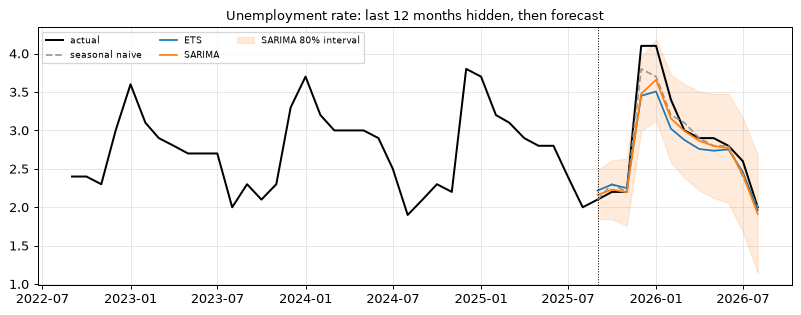

,MAE,MASE
계절 naive,0.117,0.378
ETS,0.212,0.686
SARIMA,0.154,0.498


In [6]:
def seasonal_naive(train):
    return np.tile(train[-12:], 2)[:H]

def ets(train):
    return ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit().forecast(H)

def sarima(train, interval=None):
    res = SARIMAX(train, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    f = res.get_forecast(H)
    if interval:                                # 예측 구간도 함께 (예: 0.8 → 80% 구간)
        ci = np.asarray(f.conf_int(alpha=1 - interval))
        return np.asarray(f.predicted_mean), ci[:, 0], ci[:, 1]
    return np.asarray(f.predicted_mean)

def mase(actual, forecast, train):
    scale = np.mean(np.abs(train[12:] - train[:-12]))      # 과거 자료에서 계절 naive의 평균 절대오차
    return np.mean(np.abs(actual - forecast)) / scale

def evaluate(fc, actual, train):
    return pd.DataFrame({name: {"MAE": np.mean(np.abs(actual - f)), "MASE": mase(actual, f, train)}
                         for name, f in fc.items()}).T

y = data["실업률"]
train, actual = y.values[:-H], y.values[-H:]
print(f"학습: {y.index[0]:%Y.%m} ~ {y.index[-H - 1]:%Y.%m} ({len(train)}개월) | 평가: {y.index[-H]:%Y.%m} ~ {y.index[-1]:%Y.%m} (12개월)")

fc = {"계절 naive": seasonal_naive(train), "ETS": ets(train)}
fc["SARIMA"], sar_lo, sar_hi = sarima(train, interval=0.8)
plot_forecasts(y, fc, band=("SARIMA", sar_lo, sar_hi), title="Unemployment rate: last 12 months hidden, then forecast")
evaluate(fc, actual, train).style.format("{:.3f}")

> ✅ **확인할 것**
> - 세 방법 모두 **계절 모양**(연초에 오르고 여름에 내림)을 따라갑니다.
> - 회색 띠는 SARIMA의 **80% 예측 구간**입니다. 통계 모형은 예측값과 함께 **불확실성**을 줍니다.
> - 표에서 어느 방법이 가장 잘 맞았나요? 저장된 결과에서는 **가장 단순한 '작년 같은 달'**(계절 naive)이 이겼습니다. 최근 1년 실업률이 전년과 거의 같은 모양으로 움직였기 때문입니다.
> - 그렇다고 계절 naive가 가장 좋은 방법일까요? 이것은 **지표 1개, 12개월 한 번**의 결과라 운이 섞여 있습니다. 5단계에서 여러 번 재 봅니다.

---
## 3단계. 신경망(MLP)을 처음부터 학습 (3분)
실습 2에서 만든 것과 같은 신경망으로 예측합니다. **과거 36개월**을 넣으면 **다음 12개월**을 한꺼번에 내놓도록 학습합니다.
- 🟦 **Data:** 학습 구간을 한 달씩 밀면서 (36개월 → 다음 12개월) 쌍을 만듭니다. 260개 남짓입니다.
- 🟩 **Model:** 36 → 64 → 12
- 🟧 **Loss:** MSE (= 정규오차 가정의 최소제곱)
- 🟥 **Optimizer:** Adam

학습용 (36개월 → 12개월) 쌍: 261개 | 가중치 수: 3,148개


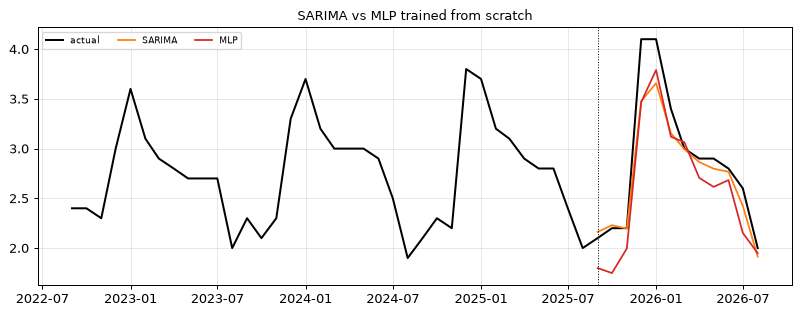

,MAE,MASE
계절 naive,0.117,0.378
ETS,0.212,0.686
SARIMA,0.154,0.498
MLP,0.278,0.901


In [7]:
def mlp(train, L=36, epochs=300, seed=SEED):
    torch.manual_seed(seed)
    mu, sd = train.mean(), train.std()
    z = (train - mu) / sd                                                   # 표준화
    # 🟦 Data: (과거 L개월 → 다음 H개월) 쌍
    X = np.array([z[i:i + L] for i in range(len(z) - L - H + 1)])
    Y = np.array([z[i + L:i + L + H] for i in range(len(z) - L - H + 1)])
    X, Y = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
    model = nn.Sequential(nn.Linear(L, 64), nn.ReLU(), nn.Linear(64, H))    # 🟩 Model
    loss_fn = nn.MSELoss()                                                  # 🟧 Loss
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)   # 🟥 Optimizer
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(X), Y)
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        return model(torch.tensor(z[-L:], dtype=torch.float32)[None])[0].numpy() * sd + mu

n_pairs = len(train) - 36 - H + 1
print(f"학습용 (36개월 → 12개월) 쌍: {n_pairs}개 | 가중치 수: {36 * 64 + 64 + 64 * H + H:,}개")
fc["MLP"] = mlp(train)
plot_forecasts(y, {k: fc[k] for k in ["SARIMA", "MLP"]}, title="SARIMA vs MLP trained from scratch")
evaluate(fc, actual, train).style.format("{:.3f}")

> ✅ **확인할 것**
> - 학습 자료가 **쌍 260개 남짓**인데 가중치는 3천 개가 넘습니다. 실습 2·3에서 본 것처럼 표본이 적으면 신경망은 불리합니다.
> - 신경망은 계절성이나 추세를 따로 알려 주지 않아도 자료에서 배우지만, 그만큼 **많은 자료**가 필요합니다. 통계 모형은 "12개월마다 반복된다"는 **구조를 처음부터 가정**합니다.

---
## 4단계. 시계열 파운데이션 모델: Chronos (5분)
**Chronos**(Amazon)는 에너지·교통·소매·경제 등 **수많은 시계열**로 미리 학습한 Transformer 모델입니다.
문장 다음 단어를 맞히는 언어모델처럼, **과거 값을 보고 다음 값들의 분포**를 내놓습니다.
**우리 지표로는 전혀 학습하지 않고** 과거 자료만 넣어서 바로 예측합니다(zero-shot). 실습 2·3·4의 사전학습 모델과 같은 발상입니다.

| 모델 | 가중치 수 | 특징 |
|---|---|---|
| `amazon/chronos-bolt-small` | 약 4,800만 | 2024년. 빠르고 가벼움 |
| `amazon/chronos-2` | 약 1억 2천만 | 2025년. 여러 시계열을 함께 보고, 외부 변수도 넣을 수 있음 |

In [8]:
#@title Chronos 모델 불러오기 (처음 한 번 각 200~500MB 다운로드)
pipes = {
    "Chronos-Bolt": BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu"),
    "Chronos-2": BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map="cpu"),
}
for k, p in pipes.items():
    print(f"{k}: 가중치 {sum(x.numel() for x in p.model.parameters()) / 1e6:.0f}백만 개")

Chronos-Bolt: 가중치 48백만 개
Chronos-2: 가중치 119백만 개


예측 시간: 2.0초 (두 모델 합계)


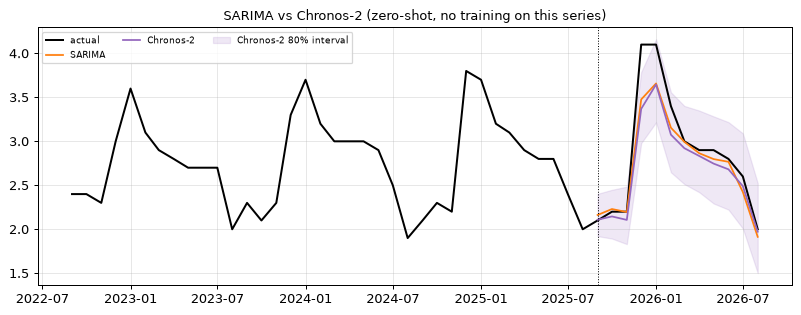

,MAE,MASE
계절 naive,0.117,0.378
ETS,0.212,0.686
SARIMA,0.154,0.498
MLP,0.278,0.901
Chronos-Bolt,0.358,1.159
Chronos-2,0.185,0.599


In [9]:
QUANTILES = [0.1, 0.5, 0.9]      # 10%, 50%(중앙값), 90% 분위수 → 10~90% 사이가 80% 예측 구간

def chronos_forecast(pipe, contexts, h=H, quantiles=QUANTILES):
    """과거 자료 목록 → (자료 수, h개월, 분위수 수) 배열. 학습은 하지 않습니다."""
    if isinstance(pipe, Chronos2Pipeline):
        qs, _ = pipe.predict_quantiles([torch.tensor(c, dtype=torch.float32)[None] for c in contexts],
                                       prediction_length=h, quantile_levels=quantiles)
        return np.stack([q[0].numpy() for q in qs])
    qs, _ = pipe.predict_quantiles([torch.tensor(c, dtype=torch.float32) for c in contexts],
                                   prediction_length=h, quantile_levels=quantiles)
    return qs.numpy()

t = time.time()
cq = {k: chronos_forecast(p, [train])[0] for k, p in pipes.items()}     # 학습 없이 바로 예측
print(f"예측 시간: {time.time() - t:.1f}초 (두 모델 합계)")
for k, q in cq.items():
    fc[k] = q[:, 1]                                                        # 중앙값을 예측값으로
plot_forecasts(y, {k: fc[k] for k in ["SARIMA", "Chronos-2"]}, band=("Chronos-2", cq["Chronos-2"][:, 0], cq["Chronos-2"][:, 2]),
               title="SARIMA vs Chronos-2 (zero-shot, no training on this series)")
evaluate(fc, actual, train).style.format("{:.3f}").background_gradient(cmap="Greens_r", subset=["MASE"])

> ✅ **확인할 것**
> - **Chronos-2**는 이 지표를 한 번도 학습하지 않았는데 계절 모양과 수준을 그럴듯하게 이어 가고, 예측 구간(분위수)도 함께 줍니다. 예측은 1초 안팎이면 끝납니다.
> - 저장된 결과에서 Chronos-2는 SARIMA와 ETS 사이였고, 한 세대 전 모델인 **Chronos-Bolt는 이번 시험에서 가장 나빴습니다.**
> - 다시 말하지만 **지표 1개, 12개월 한 번**의 결과입니다. 한 번의 시험으로 모델을 고르면 안 됩니다. → 5단계

---
## 5단계. 공정한 비교: 지표 4개 × 예측 시점 8개 (4분)
한 번의 시험은 운이 섞입니다. 그래서 **예측 시작 시점을 3개월씩 앞당기며 8번** 예측하고(rolling origin), **지표 4개**에 모두 해 봅니다. 4 × 8 = 32번의 12개월 예측을 평균합니다.
통계로 말하면 **표본을 늘려서 비교의 분산을 줄이는 것**입니다. 실습 3에서 라벨 수 곡선을 5번 반복한 것과 같은 이유입니다.

마지막 줄의 **평균** (ETS+SARIMA+Chronos-2)는 세 예측을 단순 평균한 것입니다(예측 결합).

In [10]:
ORIGINS = 8          # 예측 시점 8개 (3개월 간격)
STATS = {"계절 naive": seasonal_naive, "ETS": ets, "SARIMA": sarima, "MLP": mlp}

t = time.time()
rows, store = [], {}
for k, s in data.items():
    v = s.values
    cuts = [len(v) - H - 3 * o for o in range(ORIGINS)]
    # Chronos는 시점 8개를 한꺼번에 예측 (학습이 없어 빠름)
    cq_all = {m: chronos_forecast(p, [v[:c] for c in cuts]) for m, p in pipes.items()}
    for o, c in enumerate(cuts):
        tr, te = v[:c], v[c:c + H]
        f = {m: np.asarray(fn(tr)) for m, fn in STATS.items()}
        f.update({m: q[o][:, 1] for m, q in cq_all.items()})
        f["평균 (ETS+SARIMA+Chronos-2)"] = (f["ETS"] + f["SARIMA"] + f["Chronos-2"]) / 3
        store[(k, o)] = (tr, te, cq_all, f)
        for m, fm in f.items():
            rows.append({"지표": k, "시점": o, "방법": m, "MASE": mase(te, fm, tr)})
R = pd.DataFrame(rows)
print(f"예측 {len(R):,}번 | {time.time() - t:.0f}초")

table = R.pivot_table(index="방법", columns="지표", values="MASE", aggfunc="mean")[list(data)]
table["평균 MASE"] = table.mean(axis=1)
table["평균 순위"] = R.assign(rank=R.groupby(["지표", "시점"])["MASE"].rank()).groupby("방법")["rank"].mean()
table.sort_values("평균 MASE").style.format("{:.2f}").background_gradient(cmap="Greens_r", subset=["평균 MASE", "평균 순위"])

예측 224번 | 7초


지표,실업률,취업자,소매판매,제조업생산,평균 MASE,평균 순위
방법,,,,,,
ETS,0.65,0.29,0.63,1.03,0.65,3.00
평균 (ETS+SARIMA+Chronos-2),0.53,0.28,0.79,1.06,0.66,2.88
SARIMA,0.55,0.29,0.84,1.12,0.70,3.47
Chronos-2,0.54,0.39,0.92,1.07,0.73,3.84
계절 naive,0.45,0.46,0.75,1.35,0.75,3.78
Chronos-Bolt,0.98,0.46,1.12,1.06,0.90,5.34
MLP,1.12,0.51,1.36,1.13,1.03,5.69


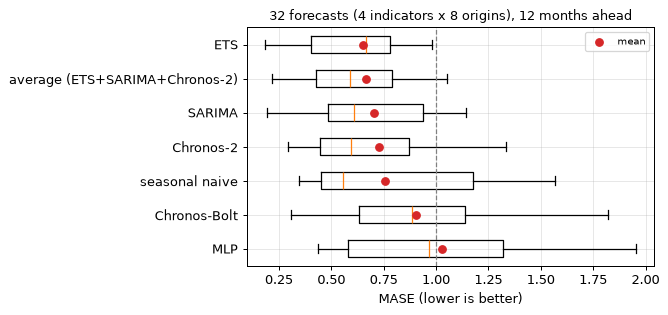

In [11]:
order = table.sort_values("평균 MASE").index
en = {**LABEL_EN, "평균 (ETS+SARIMA+Chronos-2)": "average (ETS+SARIMA+Chronos-2)"}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
box = [R[R["방법"] == m]["MASE"].values for m in order]
ax.boxplot(box, vert=False, tick_labels=[en.get(m, m) for m in order], showfliers=False)
ax.scatter(table.loc[order, "평균 MASE"], range(1, len(order) + 1), color="C3", zorder=3, label="mean")
ax.axvline(1, color="gray", ls="--", lw=1)
ax.invert_yaxis(); ax.set_xlabel("MASE (lower is better)")
ax.set_title("32 forecasts (4 indicators x 8 origins), 12 months ahead", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

> ✅ **확인할 것**
> - 이런 **월별 지표 하나하나**에서는 **ETS·SARIMA 같은 통계 모형이 여전히 강합니다.** 수십 년 써 온 데는 이유가 있습니다.
> - **Chronos-2**는 학습 없이도 통계 모형과 비슷한 수준까지 옵니다. 한 세대 전 모델(Chronos-Bolt)보다 확실히 좋아졌습니다.
> - **MLP를 처음부터** 학습한 것은 가장 불리합니다. 지표 하나당 자료가 수백 개뿐이기 때문입니다.
> - '작년 같은 달'(계절 naive)도 만만치 않습니다. 지표에 따라서는 1등입니다. 새 모델은 **반드시 단순한 기준선과 같이** 비교합니다.
> - 상자(32번의 흩어짐)가 넓습니다. 어느 방법이든 **잘 맞는 때와 크게 틀리는 때**가 있습니다.
> - 여러 방법을 **평균**하면 대체로 안정적입니다. 예측 결합(forecast combination)은 통계학에서 오래된 지혜입니다.

### 5-1. ✏️ 모델 크기 바꿔 보기
Chronos-Bolt는 크기가 여러 가지입니다. 같은 32번의 예측으로 크기만 바꿔 봅니다.

In [12]:
SIZES = ["amazon/chronos-bolt-tiny", "amazon/chronos-bolt-small", "amazon/chronos-bolt-base", "amazon/chronos-2"]

size_rows = []
for name in SIZES:
    p = pipes["Chronos-2"] if name.endswith("chronos-2") else BaseChronosPipeline.from_pretrained(name, device_map="cpu")
    t = time.time(); scores_ = []
    for k, s in data.items():
        v = s.values
        cuts = [len(v) - H - 3 * o for o in range(ORIGINS)]
        q = chronos_forecast(p, [v[:c] for c in cuts])
        scores_ += [mase(v[c:c + H], q[o][:, 1], v[:c]) for o, c in enumerate(cuts)]
    size_rows.append({"모델": name.split("/")[1], "가중치 수(백만)": sum(x.numel() for x in p.model.parameters()) / 1e6,
                      "평균 MASE": np.mean(scores_), "예측 32번 시간(초)": time.time() - t})
pd.DataFrame(size_rows).set_index("모델").style.format({"가중치 수(백만)": "{:.0f}", "평균 MASE": "{:.2f}", "예측 32번 시간(초)": "{:.1f}"})

,가중치 수(백만),평균 MASE,예측 32번 시간(초)
모델,,,
chronos-bolt-tiny,9,0.99,0.1
chronos-bolt-small,48,0.90,0.1
chronos-bolt-base,205,0.85,3.2
chronos-2,119,0.73,0.3


> ✅ **확인할 것**
> - 같은 세대(Bolt) 안에서는 크기를 20배 넘게 키우면 조금씩 좋아지지만, 시간도 늘어납니다.
> - 크기가 Bolt-base의 절반쯤인 **다음 세대 Chronos-2가 가장 큰 Bolt보다 낫습니다.** 크기보다 **세대**(학습 방법·데이터)의 차이가 큽니다. 실습 3·4에서 본 것과 같은 결론입니다.

---
## 6단계. 예측 구간은 믿을 만한가? (3분)
80% 예측 구간이라면, 실제값의 **약 80%가 구간 안에** 들어와야 합니다. 5단계의 32번 × 12개월 = 384개 실제값으로 확인합니다.
통계 모형의 구간은 **모형 가정**(정규오차 등)에서, Chronos의 구간은 **학습한 분위수**에서 나옵니다.

In [13]:
cover = {"SARIMA": [], "Chronos-Bolt": [], "Chronos-2": []}
width = {k: [] for k in cover}
for (k, o), (tr, te, cq_all, f) in store.items():
    _, lo, hi = sarima(tr, interval=0.8)
    scale = np.mean(np.abs(tr[12:] - tr[:-12]))
    cover["SARIMA"] += list((te >= lo) & (te <= hi)); width["SARIMA"] += list((hi - lo) / scale)
    for m in ["Chronos-Bolt", "Chronos-2"]:
        q = cq_all[m][o]
        cover[m] += list((te >= q[:, 0]) & (te <= q[:, 2])); width[m] += list((q[:, 2] - q[:, 0]) / scale)

pd.DataFrame({"80% 구간 안에 든 비율": {k: np.mean(v) for k, v in cover.items()},
              "구간 폭 (계절 naive 오차 대비)": {k: np.mean(v) for k, v in width.items()}}) \
  .style.format({"80% 구간 안에 든 비율": "{:.0%}", "구간 폭 (계절 naive 오차 대비)": "{:.2f}"})

,80% 구간 안에 든 비율,구간 폭 (계절 naive 오차 대비)
SARIMA,82%,2.59
Chronos-Bolt,78%,2.80
Chronos-2,79%,2.32


> ✅ **확인할 것**
> - 80%에 가까울수록 구간이 **정직**합니다. 80%보다 많이 낮으면 **자신만만한**(구간이 너무 좁은) 모델입니다.
> - 구간 폭도 함께 봅니다. 둘 다 80% 근처라면 **좁은 쪽이 더 유용**합니다.
> - 저장된 결과에서는 세 모델 모두 80% 근처였고, 그중 **Chronos-2의 구간이 가장 좁았습니다.**
> - 정확도(5단계)만이 아니라 **불확실성을 제대로 말해 주는지**도 모델 선택 기준입니다. 공식 통계에서는 특히 중요합니다.

---
## 7단계. 예측으로 이상값 찾기: 내검에 쓰기 (3분)
새 달의 값이 들어왔을 때 "**지난 자료로 본 예상 범위**"를 크게 벗어나면 검토 대상으로 표시할 수 있습니다.
**취업자 수**로 2015년부터 매달 **한 달 앞 예측**을 하고, 실제값이 **98% 예측 구간**(1%~99% 분위수) 밖이면 표시합니다.

한 달 앞 예측 140번 | 1.1초


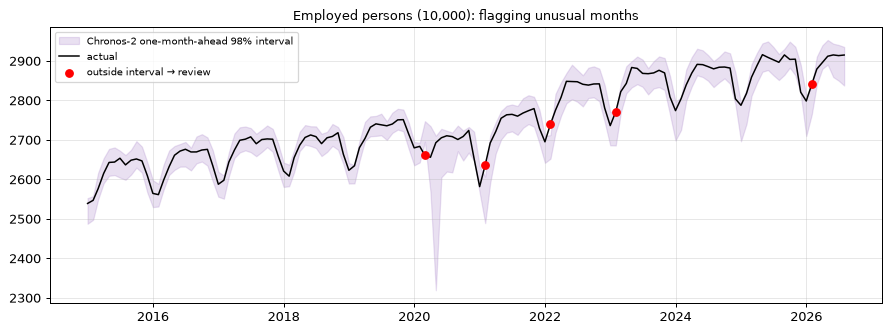

,실제값(만 명),예측 중앙값,하한(1%),상한(99%)
월,,,,
2020.03,"2,660.9","2,722.6","2,695.6","2,747.6"
2021.02,"2,636.5","2,577.1","2,489.3","2,607.2"
2022.02,"2,740.2","2,692.0","2,652.6","2,712.3"
2023.02,"2,771.4","2,744.7","2,686.1","2,768.7"
2026.02,"2,841.2","2,812.4","2,765.0","2,834.1"


In [14]:
s = data["취업자"]
v = s.values
start = list(s.index).index(pd.Timestamp("2015-01-01"))
t = time.time()
q = chronos_forecast(pipes["Chronos-2"], [v[:i] for i in range(start, len(v))], h=1, quantiles=[0.01, 0.5, 0.99])[:, 0, :]
print(f"한 달 앞 예측 {len(q)}번 | {time.time() - t:.1f}초")

actual_1 = v[start:]
flag = (actual_1 < q[:, 0]) | (actual_1 > q[:, 2])
idx = s.index[start:]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(idx, q[:, 0], q[:, 2], color="C4", alpha=0.2, label="Chronos-2 one-month-ahead 98% interval")
ax.plot(idx, actual_1, "k", lw=1.2, label="actual")
ax.scatter(idx[flag], actual_1[flag], color="red", zorder=3, label="outside interval → review")
ax.set_title("Employed persons (10,000): flagging unusual months", fontsize=10); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

q = q.astype(float)
pd.DataFrame({"실제값(만 명)": actual_1[flag], "예측 중앙값": q[flag, 1], "하한(1%)": q[flag, 0], "상한(99%)": q[flag, 2]},
             index=pd.Index(idx[flag].strftime("%Y.%m"), name="월")).style.format("{:,.1f}")

> ✅ **확인할 것**
> - 2020년 3월(코로나19 첫 충격)처럼 **실제로 큰일이 있었던 달**이 표시되나요? 저장된 결과에서는 그 밖에 **몇몇 해의 2월**이 예상보다 높게 나와 표시되었습니다.
> - 표시된 달이 모두 '오류'는 아닙니다. **실제 변화일 수도, 입력 오류일 수도** 있습니다. 모델은 **검토할 곳을 좁혀 줄 뿐**이고, 판단은 담당자가 합니다.
> - 구간을 넓히면(예: 99.8%) 표시가 줄고, 좁히면 늘어납니다. **검토 인력과 놓치면 안 되는 정도**를 보고 정합니다. 통계적 검정의 유의수준을 정하는 것과 같습니다.

---
## 마무리
| 요소 | 통계 모형 (ETS · SARIMA) | MLP (처음부터) | Chronos (파운데이션 모델) |
|---|---|---|---|
| 🟦 **Data** | 이 지표의 과거 값 | 이 지표의 (36개월 → 12개월) 쌍 260여 개 | 수많은 시계열로 사전학습 + 이 지표의 과거 값(입력만) |
| 🟩 **Model** | 계절·추세 구조를 가정한 식, 모수 몇 개 | 36 → 64 → 12, 가중치 3천여 개 | Transformer, 가중치 수천만~1억 개 (고정) |
| 🟧 **Loss** | 우도 (정규오차) | MSE | 분위수 손실 (사전학습 때) |
| 🟥 **Optimizer** | 최대우도 수치최적화 | Adam | (우리 자료로는 학습 안 함) |

### 오늘의 핵심
1. **지표 하나하나의 월별 예측**에서는 통계 모형이 여전히 강하고, **처음부터 학습한 신경망**은 자료가 모자라 불리합니다.
2. **시계열 파운데이션 모델**은 학습 없이도 통계 모형 가까이 옵니다. 세대가 바뀌며 빠르게 좋아지고 있습니다.
3. 모델은 **여러 번(여러 지표, 여러 시점)** 재서 비교합니다. 한 번의 결과로 고르지 않습니다.
4. **예측 구간이 정직한지**도 봅니다. 예측은 **내검**(이상값 검토)에도 쓸 수 있습니다.

### 국가통계와의 연결
- **쓸 수 있는 곳**: 수많은 세부 지표(지역 × 산업 × 품목)를 한꺼번에 예측해야 할 때, 모형을 하나하나 만들 수 없으면 파운데이션 모델이 좋은 출발점입니다. 속보치·잠정치 추정(nowcasting), 결측 보완, 내검에도 씁니다.
- **주의할 점**
  - 공표 수치에 쓰려면 **설명 가능성과 재현성**이 필요합니다. 모델 버전을 고정하고, 통계 모형과 함께 비교·기록합니다.
  - **구조 변화**(제도 변경, 기준년 개편, 코로나19 같은 충격)는 어떤 모델도 미리 알지 못합니다. 담당자의 판단이 필요합니다.

In [15]:
print(f"전체 실행 시간: {time.time() - t_start:.0f}초")

전체 실행 시간: 22초
